In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
import yfinance as yf

# Value at Risk with Backtesting

## Data and Portfolio Returns

In [6]:
tickers = ["NESN.SW", "NOVN.SW", "UBSG.SW", "ZURN.SW"]
prices = yf.download(tickers, start="2015-01-01", auto_adjust=True)["Close"]
prices = prices.dropna()

print(prices.tail())
print(prices.shape)

returns = prices.pct_change().dropna()
weights = np.array([0.25, 0.25, 0.25, 0.25])
port_returns = (returns*weights).sum(axis=1)

print(port_returns.describe())

[*********************100%***********************]  4 of 4 completed

Ticker        NESN.SW     NOVN.SW    UBSG.SW     ZURN.SW
Date                                                    
2026-11-03  84.410004  131.500000  39.470001  625.400024
2026-11-04  85.900002  134.259995  41.279999  637.599976
2026-11-05  87.230003  134.119995  39.889999  643.799988
2026-11-06  85.849998  133.080002  39.540001  630.200012
2026-11-09  86.129997  133.460007  39.959999  632.599976
(2980, 4)
count    2979.000000
mean        0.000452
std         0.010304
min        -0.107560
25%        -0.004364
50%         0.000673
75%         0.005698
max         0.079883
dtype: float64


## VaR and Expected Shortfall

In [7]:
alpha = 0.01

# 1) historic simulation
q = port_returns.quantile(alpha)
var_hist = -q
es_hist = -port_returns[port_returns <= q].mean()

# 2) parametic
mu = port_returns.mean()
sigma = port_returns.std()
z = norm.ppf(alpha)
var_param = -(mu + z * sigma)
es_param = -mu + sigma * norm.pdf(z) / alpha

print(f"Historical  VaR 99%: {var_hist:.2%}   ES 99%: {es_hist:.2%}")
print(f"Parametric  VaR 99%: {var_param:.2%}   ES 99%: {es_param:.2%}")

Historical  VaR 99%: 3.18%   ES 99%: 4.48%
Parametric  VaR 99%: 2.35%   ES 99%: 2.70%


Excess kurtosis: 10.24   (Normal distribution = 0)


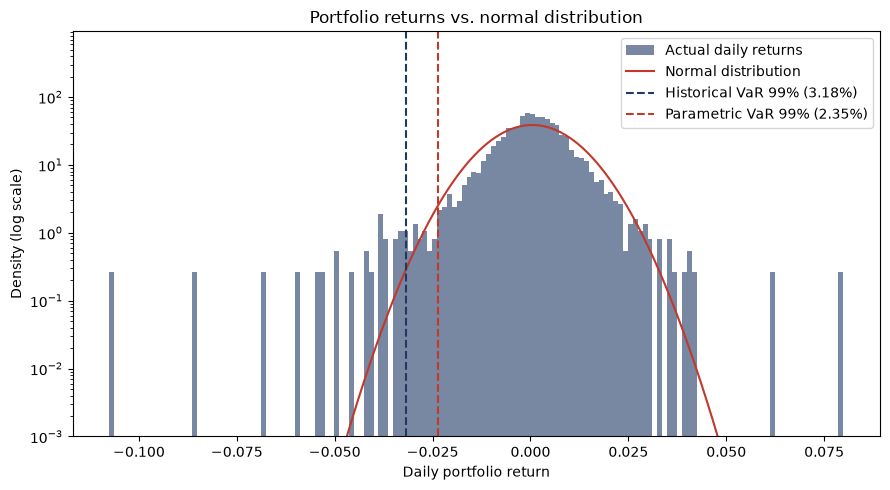

In [10]:
print(f"Excess kurtosis: {port_returns.kurt():.2f}   (Normal distribution = 0)")

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(port_returns, bins=150, density=True, color="#1F3864", alpha=0.6,
        label="Actual daily returns")
x = np.linspace(port_returns.min(), port_returns.max(), 500)
ax.plot(x, norm.pdf(x, mu, sigma), color="#C0392B", linewidth=1.5,
        label="Normal distribution")
ax.axvline(-var_hist, color="#1F3864", linestyle="--",
           label=f"Historical VaR 99% ({var_hist:.2%})")
ax.axvline(-var_param, color="#C0392B", linestyle="--",
           label=f"Parametric VaR 99% ({var_param:.2%})")

ax.set_yscale("log")
ax.set_xlabel("Daily portfolio return")
ax.set_ylabel("Density (log scale)")
ax.set_title("Portfolio returns vs. normal distribution")
ax.set_ylim(1e-3, None)
ax.legend()

fig.tight_layout()
fig.savefig("return_distribution.png", dpi=200)
plt.show()

### Rolling Backtest

In [12]:
window = 250

var_hist_roll = -port_returns.rolling(window).quantile(alpha).shift(1)

roll_mu = port_returns.rolling(window).mean()
roll_sigma = port_returns.rolling(window).std()
var_param_roll = -(roll_mu + z * roll_sigma).shift(1)

bt = pd.DataFrame({
    "ret": port_returns,
    "var_hist": var_hist_roll,
    "var_param": var_param_roll,
}).dropna()

bt["exc_hist"] = bt["ret"] < -bt["var_hist"]
bt["exc_param"] = bt["ret"] < -bt["var_param"]

n = len(bt)
print(f"Backtest days: {n}, expected exceptions at 1%: {alpha * n:.1f}")
print(f"Historical: {bt['exc_hist'].sum()} exceptions ({bt['exc_hist'].mean():.2%})")
print(f"Parametric: {bt['exc_param'].sum()} exceptions ({bt['exc_param'].mean():.2%})")

Backtest days: 2729, expected exceptions at 1%: 27.3
Historical: 38 exceptions (1.39%)
Parametric: 55 exceptions (2.02%)


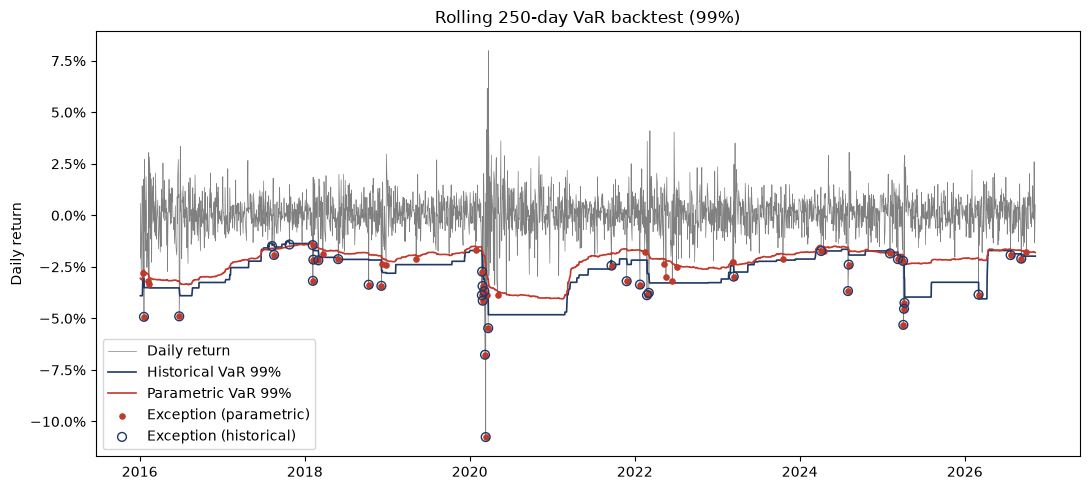

In [13]:
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(bt.index, bt["ret"], color="grey", linewidth=0.5, label="Daily return")
ax.plot(bt.index, -bt["var_hist"], color="#1F3864", linewidth=1.2, label="Historical VaR 99%")
ax.plot(bt.index, -bt["var_param"], color="#C0392B", linewidth=1.2, label="Parametric VaR 99%")

exc_p = bt[bt["exc_param"]]
exc_h = bt[bt["exc_hist"]]
ax.scatter(exc_p.index, exc_p["ret"], color="#C0392B", s=14, zorder=3,
           label="Exception (parametric)")
ax.scatter(exc_h.index, exc_h["ret"], facecolors="none", edgecolors="#1F3864",
           s=40, zorder=4, label="Exception (historical)")

ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel("Daily return")
ax.set_title("Rolling 250-day VaR backtest (99%)")
ax.legend(loc="lower left")

fig.tight_layout()
fig.savefig("var_backtest.png", dpi=200)
plt.show()

### Kupiec-Test

In [16]:
from scipy.stats import chi2

def kupiec_test(x, n, p=0.01):
    """Kupiec proportion-of-failures test. Returns LR statistic and p-value."""
    phat = x / n
    log_l0 = (n - x) * np.log(1 - p) + x * np.log(p)
    log_l1 = (n - x) * np.log(1 - phat) + x * np.log(phat)
    lr = -2 * (log_l0 - log_l1)
    p_value = 1 - chi2.cdf(lr, df=1)
    return lr, p_value

for name, col in [("Historical", "exc_hist"), ("Parametric", "exc_param")]:
    x = bt[col].sum()
    lr, pv = kupiec_test(x, n, alpha)
    decision = "reject" if pv < 0.05 else "do not reject"
    print(f"{name}: {x} exceptions, LR = {lr:.2f}, p-value = {pv:.4f} -> {decision}")

Historical: 38 exceptions, LR = 3.78, p-value = 0.0518 -> do not reject
Parametric: 55 exceptions, LR = 21.95, p-value = 0.0000 -> reject


#### Basel Traffic Light Test

In [17]:
def basel_zone(k):
    if k <= 4:
        return "green"
    elif k <= 9:
        return "yellow"
    else:
        return "red"

yearly = bt.groupby(bt.index.year)[["exc_hist", "exc_param"]].sum()
yearly["days"] = bt.groupby(bt.index.year).size()
yearly["zone_hist"] = yearly["exc_hist"].apply(basel_zone)
yearly["zone_param"] = yearly["exc_param"].apply(basel_zone)

print(yearly)

      exc_hist  exc_param  days zone_hist zone_param
Date                                                
2016         2          5   254     green     yellow
2017         3          1   251     green      green
2018         7         10   249    yellow        red
2019         0          1   249     green      green
2020         8         11   252    yellow        red
2021         2          2   254     green      green
2022         3          8   254     green     yellow
2023         1          3   251     green      green
2024         3          4   250     green      green
2025         6          6   249    yellow     yellow
2026         3          4   216     green      green


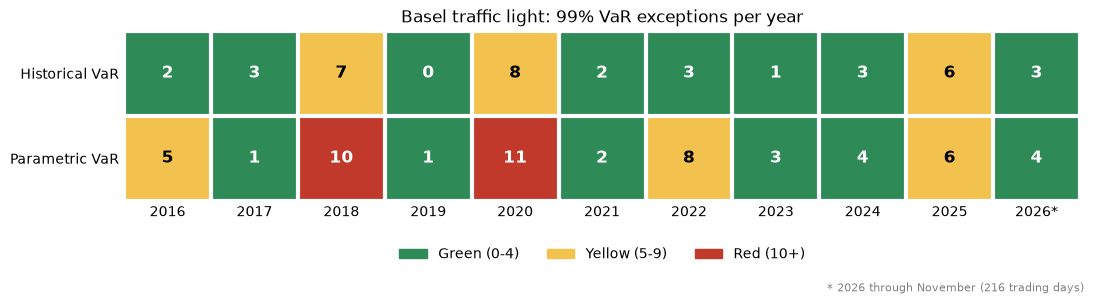

In [ ]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

zone_to_num = {"green": 0, "yellow": 1, "red": 2}
grid = np.array([
    yearly["zone_hist"].map(zone_to_num),
    yearly["zone_param"].map(zone_to_num),
])
counts = np.array([yearly["exc_hist"], yearly["exc_param"]])

cmap = ListedColormap(["#2E8B57", "#F2C14E", "#C0392B"])

fig, ax = plt.subplots(figsize=(11, 3))
ax.imshow(grid, cmap=cmap, vmin=0, vmax=2, aspect="auto")

for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        text_color = "black" if grid[i, j] == 1 else "white"
        ax.text(j, i, str(counts[i, j]), ha="center", va="center",
                color=text_color, fontsize=12, fontweight="bold")

labels = [str(y) for y in yearly.index]
labels[-1] += "*"
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_yticks([0, 1])
ax.set_yticklabels(["Historical VaR", "Parametric VaR"])

ax.set_xticks(np.arange(-0.5, len(labels), 1), minor=True)
ax.set_yticks([-0.5, 0.5, 1.5], minor=True)
ax.grid(which="minor", color="white", linewidth=3)
ax.tick_params(which="both", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

legend_items = [
    Patch(color="#2E8B57", label="Green (0-4)"),
    Patch(color="#F2C14E", label="Yellow (5-9)"),
    Patch(color="#C0392B", label="Red (10+)"),
]
ax.legend(handles=legend_items, loc="upper center", bbox_to_anchor=(0.5, -0.2),
          ncol=3, frameon=False)

ax.set_title("Basel traffic light: 99% VaR exceptions per year")
fig.text(0.99, 0.01, f"* {labels[-1][:-1]} through November ({yearly['days'].iloc[-1]} trading days)",
         ha="right", fontsize=8, color="grey")

fig.tight_layout()
fig.savefig("basel_traffic_light.png", dpi=200)
plt.show()